<a href="https://colab.research.google.com/github/devarshnayyar-a11y/Research-Project-for-CSAI-Research-a-thon/blob/main/Untitled0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

IMPORTING THE MODEL

In [10]:
import gc
import torch
from diffusers import DiffusionPipeline

# Safely remove the previous model, only if it exists
if "pipe" in globals():
    del pipe

gc.collect()
torch.cuda.empty_cache()

# Load RealVisXL
pipe = DiffusionPipeline.from_pretrained(
    "SG161222/RealVisXL_V5.0",
    torch_dtype=torch.float16,
    use_safetensors=True
)

# Save GPU memory on the Colab T4
pipe.enable_model_cpu_offload()

print("Model loaded:", pipe.__class__.__name__)
print("GPU:", torch.cuda.get_device_name(0))

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Model loaded: StableDiffusionXLPipeline
GPU: Tesla T4


In [11]:
print("Kernel is responsive")
print("CUDA available:", torch.cuda.is_available())
print("Pipeline exists:", "pipe" in globals())

Kernel is responsive
CUDA available: True
Pipeline exists: True


TESTING THE MODEL ONCE ON A BASIC PROMPT

  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


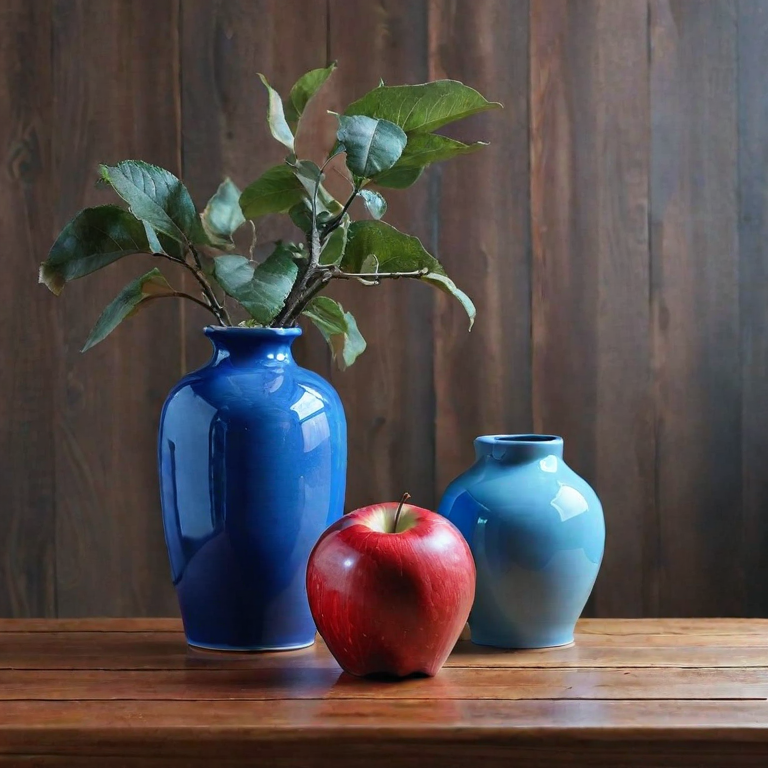

In [16]:
prompt = "A realistic photograph of exactly one red apple beside exactly one blue ceramic vase on a wooden table. Both objects are fully visible. No plants, no additional vases, and no other objects."

generator = torch.Generator(device="cpu").manual_seed(42)

result = pipe(
    prompt=prompt,
    width=768,
    height=768,
    num_inference_steps=30,
    guidance_scale=12,
    generator=generator
)

test_image = result.images[0]
display(test_image)

Yeah above image has duplicate vases so our cross attention reweighting mechanism would help later in it

CAPTURING ATTENTION MAPS

In [17]:

import torch
from pathlib import Path
from diffusers.models.attention_processor import Attention


class AttentionStore:
    """Stores conditional cross-attention maps by step and layer."""

    def __init__(self):
        self.reset()

    def reset(self):
        # step -> layer name -> tensor [spatial_queries, text_tokens]
        self.maps = {}
        self.step_idx = 0

    def add(self, layer_name, attention_map):
        self.maps.setdefault(self.step_idx, {})[layer_name] = (
            attention_map.detach().to(
                device="cpu", dtype=torch.float16
            )
        )

    def next_step(self):
        self.step_idx += 1


class StoringAttnProcessor:
    """
    Captures cross-attention probabilities while preserving
    the ordinary attention operation. Does not reweight attention.
    """

    def __init__(self, store, layer_name, max_query_positions=4096):
        self.store = store
        self.layer_name = layer_name
        self.max_query_positions = max_query_positions

    def __call__(
        self,
        attn,
        hidden_states,
        encoder_hidden_states=None,
        attention_mask=None,
        temb=None,
        **kwargs,
    ):
        residual = hidden_states
        input_ndim = hidden_states.ndim

        # Handle spatial feature maps.
        if attn.spatial_norm is not None:
            hidden_states = attn.spatial_norm(hidden_states, temb)

        if input_ndim == 4:
            batch_size, channels, height, width = hidden_states.shape
            hidden_states = hidden_states.view(
                batch_size, channels, height * width
            ).transpose(1, 2)
        else:
            batch_size = hidden_states.shape[0]

        if attn.group_norm is not None:
            hidden_states = attn.group_norm(
                hidden_states.transpose(1, 2)
            ).transpose(1, 2)

        is_cross_attention = encoder_hidden_states is not None

        context = (
            encoder_hidden_states
            if is_cross_attention
            else hidden_states
        )

        if is_cross_attention and attn.norm_cross:
            context = attn.norm_encoder_hidden_states(context)

        query = attn.to_q(hidden_states)
        key = attn.to_k(context)
        value = attn.to_v(context)

        query = attn.head_to_batch_dim(query)
        key = attn.head_to_batch_dim(key)
        value = attn.head_to_batch_dim(value)

        attention_mask = attn.prepare_attention_mask(
            attention_mask,
            key.shape[1],
            batch_size,
        )

        attention_probs = attn.get_attention_scores(
            query, key, attention_mask
        )

        # Capture cross-attention only, not self-attention.
        # Under classifier-free guidance, the last batch entry
        # is the conditional branch for the standard SDXL pipeline.
        query_positions = attention_probs.shape[1]

        if (
            is_cross_attention
            and query_positions <= self.max_query_positions
        ):
            heads = attn.heads
            text_tokens = attention_probs.shape[-1]

            probs = attention_probs.reshape(
                batch_size,
                heads,
                query_positions,
                text_tokens,
            )

            conditional_map = probs[-1].mean(dim=0)

            self.store.add(
                self.layer_name,
                conditional_map,
            )

        # Standard attention computation: no intervention here.
        hidden_states = torch.bmm(attention_probs, value)
        hidden_states = attn.batch_to_head_dim(hidden_states)

        hidden_states = attn.to_out[0](hidden_states)
        hidden_states = attn.to_out[1](hidden_states)

        if input_ndim == 4:
            hidden_states = hidden_states.transpose(1, 2).reshape(
                batch_size, channels, height, width
            )

        if attn.residual_connection:
            hidden_states = hidden_states + residual

        hidden_states = hidden_states / attn.rescale_output_factor

        return hidden_states


def install_attention_capture(pipeline, store, max_query_positions=4096):
    """Replace cross-attention processors and preserve all others."""

    original_processors = dict(pipeline.unet.attn_processors)
    new_processors = {}

    for name, original in original_processors.items():
        if name.endswith("attn2.processor"):
            layer_name = name.removesuffix(".processor")
            new_processors[name] = StoringAttnProcessor(
                store,
                layer_name,
                max_query_positions=max_query_positions,
            )
        else:
            new_processors[name] = original

    pipeline.unet.set_attn_processor(new_processors)

    return original_processors


def restore_attention_processors(pipeline, original_processors):
    """Restore the pipeline's original processors."""
    pipeline.unet.set_attn_processor(original_processors)


def make_attention_step_callback(store):
    """Advance the attention-store index after each denoising step."""

    def callback(pipeline, step_index, timestep, callback_kwargs):
        store.next_step()
        return callback_kwargs

    return callback


print("Attention capture classes and helper functions are ready.")


Attention capture classes and helper functions are ready.


TESTING ATTENTION CAPTURING ON A GENERATED IMAGE

  0%|          | 0/20 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Image saved: attention_capture/apple_vase_seed7_cfg7.5_steps20.png
Attention data saved: attention_capture/attention_seed7_cfg7.5_steps20.pt
Denoising steps captured: 20
Layers captured at first step: 70
Example layer: down_blocks.1.attentions.0.transformer_blocks.0.attn2
Example map shape: (2304, 77)


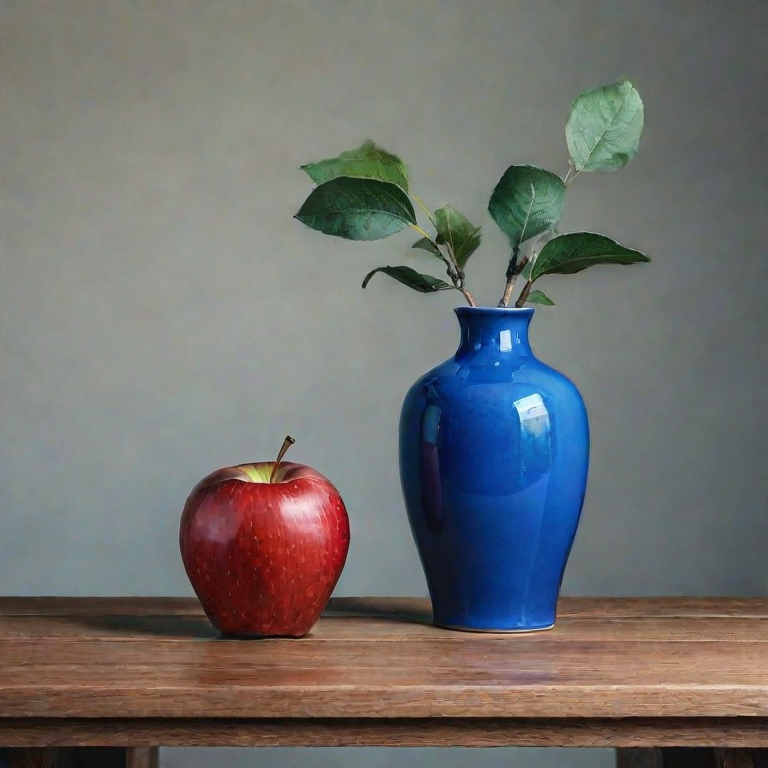

In [18]:

import torch
from pathlib import Path
from IPython.display import display

assert "pipe" in globals(), (
    "RealVisXL pipeline 'pipe' is not loaded. Load it before running this cell."
)

OUT_DIR = Path("attention_capture")
OUT_DIR.mkdir(parents=True, exist_ok=True)

prompt = (
    "A realistic photograph of exactly one red apple beside "
    "exactly one blue ceramic vase on a wooden table. "
    "Both objects are fully visible."
)

seed = 7
cfg = 7.5
steps = 20

attention_store = AttentionStore()
original_processors = install_attention_capture(
    pipe,
    attention_store,
    max_query_positions=4096,
)

generator = torch.Generator(device="cpu").manual_seed(seed)

try:
    result = pipe(
        prompt=prompt,
        width=768,
        height=768,
        num_inference_steps=steps,
        guidance_scale=cfg,
        generator=generator,
        callback_on_step_end=make_attention_step_callback(
            attention_store
        ),
    )
    image = result.images[0]

finally:
    # Always restore the original pipeline processors.
    restore_attention_processors(pipe, original_processors)

image_path = OUT_DIR / f"apple_vase_seed{seed}_cfg{cfg}_steps{steps}.png"
attention_path = OUT_DIR / f"attention_seed{seed}_cfg{cfg}_steps{steps}.pt"

image.save(image_path)
torch.save(attention_store.maps, attention_path)

print("Image saved:", image_path)
print("Attention data saved:", attention_path)
print("Denoising steps captured:", len(attention_store.maps))

if attention_store.maps:
    first_step = next(iter(attention_store.maps))
    print("Layers captured at first step:",
          len(attention_store.maps[first_step]))
    first_layer = next(iter(attention_store.maps[first_step]))
    print("Example layer:", first_layer)
    print("Example map shape:",
          tuple(attention_store.maps[first_step][first_layer].shape))

display(image)

assert attention_store.maps, (
    "No cross-attention maps were captured. Stop and inspect the error."
)


In [20]:

import torch
from pathlib import Path

# Load the saved attention maps from Cell 2
attention_path = Path(
    f"attention_capture/attention_seed{seed}_cfg{cfg}_steps{steps}.pt"
)

assert attention_path.exists(), (
    f"Attention file not found: {attention_path}. "
    "Run Cell 2 successfully first."
)

attention_data = torch.load(
    attention_path,
    map_location="cpu",
    weights_only=False
)

print("Attention maps loaded successfully.")
print("Denoising steps:", len(attention_data))
print("Available steps:", list(attention_data.keys()))


Attention maps loaded successfully.
Denoising steps: 20
Available steps: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


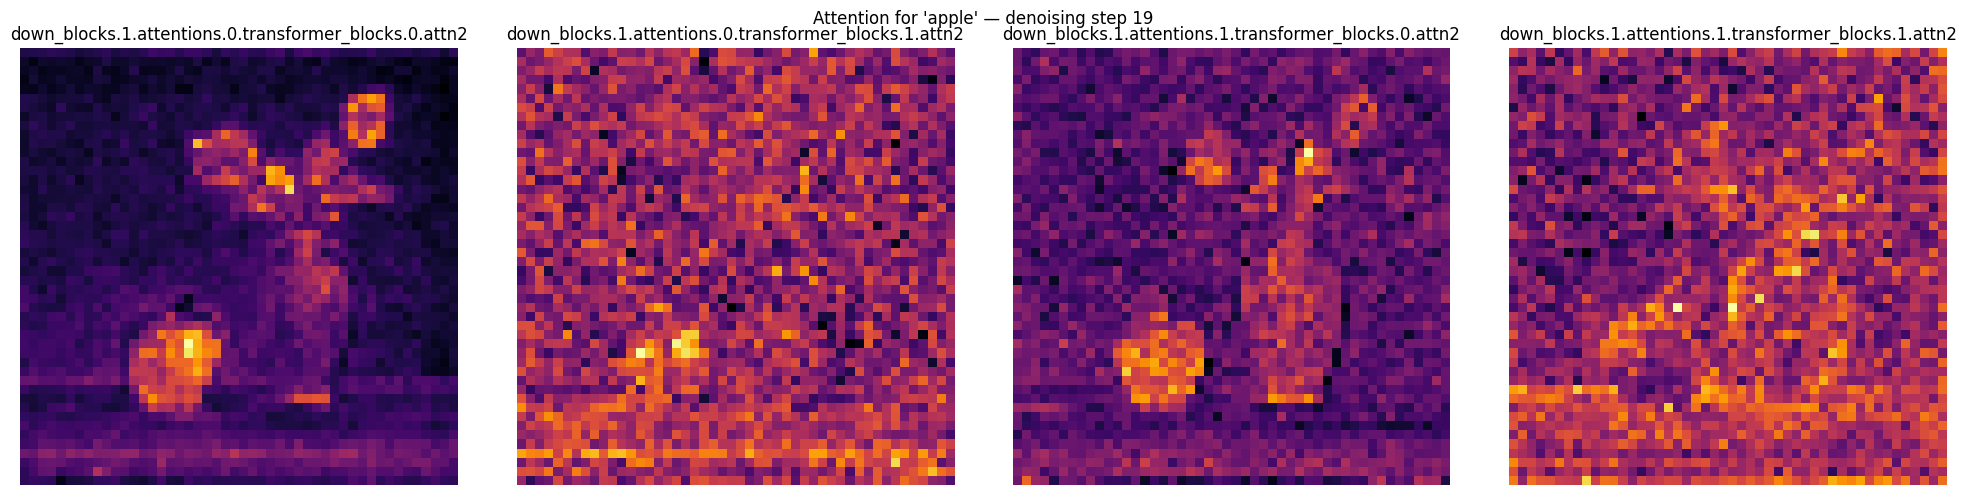

In [22]:

import torch
import matplotlib.pyplot as plt
import math

# The exact prompt used in Cell 2
prompt_text = prompt

# Tokenize the prompt using SDXL's two text encoders
tokenizers = [
    pipe.tokenizer,
    pipe.tokenizer_2
]

def find_word_token_indices(word, tokenizer, text):
    encoded = tokenizer(
        text,
        add_special_tokens=True,
        return_offsets_mapping=True
    )
    offsets = encoded["offset_mapping"]
    start = text.lower().find(word.lower())

    if start == -1:
        raise ValueError(f"'{word}' was not found in the prompt.")

    end = start + len(word)

    return [
        i for i, (s, e) in enumerate(offsets)
        if s < end and e > start
    ]

def show_token_attention(word):
    # Find the word's token positions in both encoders
    indices_1 = find_word_token_indices(
        word, tokenizers[0], prompt_text
    )
    indices_2 = find_word_token_indices(
        word, tokenizers[1], prompt_text
    )

    # Use the captured maps from the last denoising step
    step = max(attention_data.keys())
    maps = attention_data[step]

    selected = []

    for layer_name, attn in maps.items():
        # Each map has shape [spatial positions, text tokens].
        # SDXL cross-attention layers can use either text encoder.
        if attn.shape[-1] == 77:
            token_indices = indices_1
        elif attn.shape[-1] ==  0:
            continue
        else:
            token_indices = indices_2

        valid = [i for i in token_indices if i < attn.shape[-1]]
        if not valid:
            continue

        # Average attention over the target word's subword tokens
        word_attention = attn[:, valid].float().mean(dim=-1)
        side = math.isqrt(word_attention.numel())

        if side * side == word_attention.numel():
            selected.append(
                (layer_name, word_attention.reshape(side, side).numpy())
            )

    if not selected:
        raise RuntimeError("No compatible attention maps found.")

    # Display a few layers
    selected = selected[:4]
    fig, axes = plt.subplots(
        1, len(selected), figsize=(5 * len(selected), 5)
    )
    if len(selected) == 1:
        axes = [axes]

    for ax, (name, heatmap) in zip(axes, selected):
        ax.imshow(heatmap, cmap="inferno")
        ax.set_title(name)
        ax.axis("off")

    plt.suptitle(f"Attention for '{word}' — denoising step {step}")
    plt.tight_layout()
    plt.show()

show_token_attention("apple")


In [23]:

for i, tokenizer in enumerate([pipe.tokenizer, pipe.tokenizer_2], start=1):
    encoded = tokenizer(
        prompt,
        add_special_tokens=True,
        return_offsets_mapping=True
    )

    print(f"\nText encoder {i}")
    for word in ["apple", "vase"]:
        start = prompt.lower().find(word)
        end = start + len(word)

        indices = [
            j for j, (s, e) in enumerate(encoded["offset_mapping"])
            if s < end and e > start
        ]

        tokens = tokenizer.convert_ids_to_tokens(
            [encoded["input_ids"][j] for j in indices]
        )

        print(f"{word}: indices={indices}, tokens={tokens}")



Text encoder 1
apple: indices=[8], tokens=['apple</w>']
vase: indices=[14], tokens=['vase</w>']

Text encoder 2
apple: indices=[8], tokens=['apple</w>']
vase: indices=[14], tokens=['vase</w>']


In [24]:

step = max(attention_data.keys())
maps = attention_data[step]

print("Final denoising step:", step)
print("Number of layers:", len(maps))

for name, attn in maps.items():
    print(f"{name}: shape={tuple(attn.shape)}")


Final denoising step: 19
Number of layers: 70
down_blocks.1.attentions.0.transformer_blocks.0.attn2: shape=(2304, 77)
down_blocks.1.attentions.0.transformer_blocks.1.attn2: shape=(2304, 77)
down_blocks.1.attentions.1.transformer_blocks.0.attn2: shape=(2304, 77)
down_blocks.1.attentions.1.transformer_blocks.1.attn2: shape=(2304, 77)
down_blocks.2.attentions.0.transformer_blocks.0.attn2: shape=(576, 77)
down_blocks.2.attentions.0.transformer_blocks.1.attn2: shape=(576, 77)
down_blocks.2.attentions.0.transformer_blocks.2.attn2: shape=(576, 77)
down_blocks.2.attentions.0.transformer_blocks.3.attn2: shape=(576, 77)
down_blocks.2.attentions.0.transformer_blocks.4.attn2: shape=(576, 77)
down_blocks.2.attentions.0.transformer_blocks.5.attn2: shape=(576, 77)
down_blocks.2.attentions.0.transformer_blocks.6.attn2: shape=(576, 77)
down_blocks.2.attentions.0.transformer_blocks.7.attn2: shape=(576, 77)
down_blocks.2.attentions.0.transformer_blocks.8.attn2: shape=(576, 77)
down_blocks.2.attentions.0.

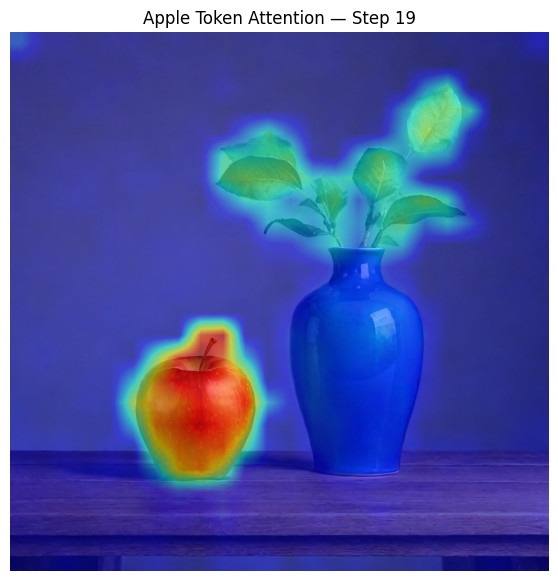

Layers averaged: 60


In [25]:

import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F

# Apple token index from your tokenizer diagnostic
token_idx = 8
spatial_positions = 576  # 24 x 24

step = max(attention_data.keys())
maps = attention_data[step]

apple_maps = [
    attn[:, token_idx].float()
    for name, attn in maps.items()
    if attn.shape == (spatial_positions, 77)
]

assert apple_maps, "No 24x24 attention maps found."

# Average across layers at the same spatial resolution
apple_attention = torch.stack(apple_maps).mean(dim=0)
apple_attention = apple_attention.reshape(24, 24)

# Normalize for visualization
apple_attention = (
    (apple_attention - apple_attention.min()) /
    (apple_attention.max() - apple_attention.min() + 1e-8)
)

plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.imshow(
    apple_attention.numpy(),
    cmap="jet",
    alpha=0.55,
    extent=(0, image.width, image.height, 0),
    interpolation="bilinear"
)
plt.title(f"Apple Token Attention — Step {step}")
plt.axis("off")
plt.show()

print("Layers averaged:", len(apple_maps))


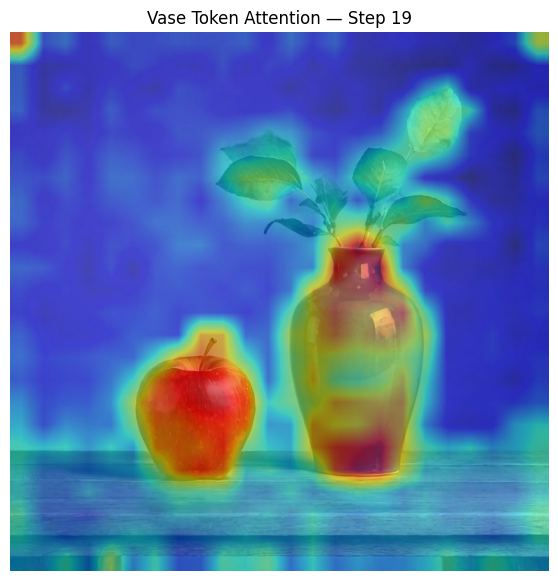

Layers averaged: 60


In [26]:

# Vase token index from your tokenizer diagnostic
token_idx = 14
spatial_positions = 576  # 24 x 24

step = max(attention_data.keys())
maps = attention_data[step]

vase_maps = [
    attn[:, token_idx].float()
    for name, attn in maps.items()
    if attn.shape == (spatial_positions, 77)
]

assert vase_maps, "No 24x24 attention maps found."

# Average across layers at the same spatial resolution
vase_attention = torch.stack(vase_maps).mean(dim=0)
vase_attention = vase_attention.reshape(24, 24)

# Normalize for visualization
vase_attention = (
    (vase_attention - vase_attention.min()) /
    (vase_attention.max() - vase_attention.min() + 1e-8)
)

plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.imshow(
    vase_attention.numpy(),
    cmap="jet",
    alpha=0.55,
    extent=(0, image.width, image.height, 0),
    interpolation="bilinear"
)
plt.title(f"Vase Token Attention — Step {step}")
plt.axis("off")
plt.show()

print("Layers averaged:", len(vase_maps))


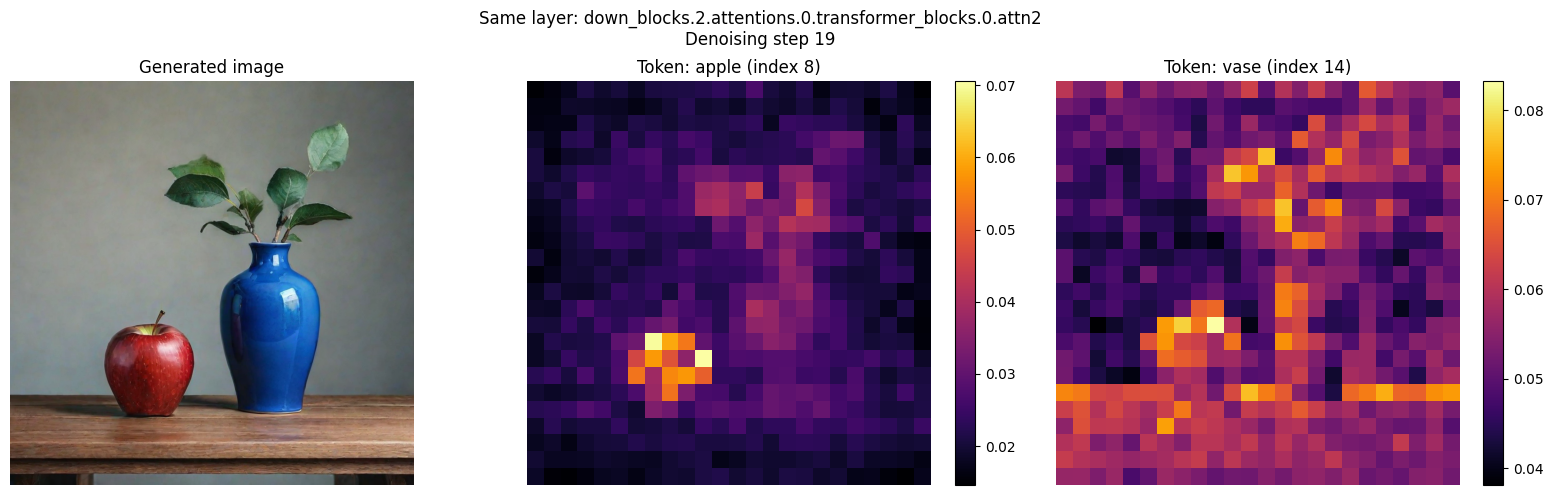

Layer: down_blocks.2.attentions.0.transformer_blocks.0.attn2
Apple attention range: 0.0146102905 0.07055664
Vase attention range: 0.038146973 0.08325195


In [28]:

import matplotlib.pyplot as plt
import torch
import math

step = max(attention_data.keys())
maps = attention_data[step]

# Select one 24 x 24 cross-attention layer
candidates = [
    (name, attn)
    for name, attn in maps.items()
    if attn.shape == (576, 77)
]

assert candidates, "No 24 x 24 attention maps found."

layer_name, attn = candidates[0]

# Extract the individual token maps from the same layer
apple_map = attn[:, 8].float().reshape(24, 24).numpy()
vase_map = attn[:, 14].float().reshape(24, 24).numpy()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(image)
axes[0].set_title("Generated image")
axes[0].axis("off")

im1 = axes[1].imshow(apple_map, cmap="inferno")
axes[1].set_title("Token: apple (index 8)")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

im2 = axes[2].imshow(vase_map, cmap="inferno")
axes[2].set_title("Token: vase (index 14)")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.suptitle(f"Same layer: {layer_name}\nDenoising step {step}")
plt.tight_layout()
plt.show()

print("Layer:", layer_name)
print("Apple attention range:", apple_map.min(), apple_map.max())
print("Vase attention range:", vase_map.min(), vase_map.max())


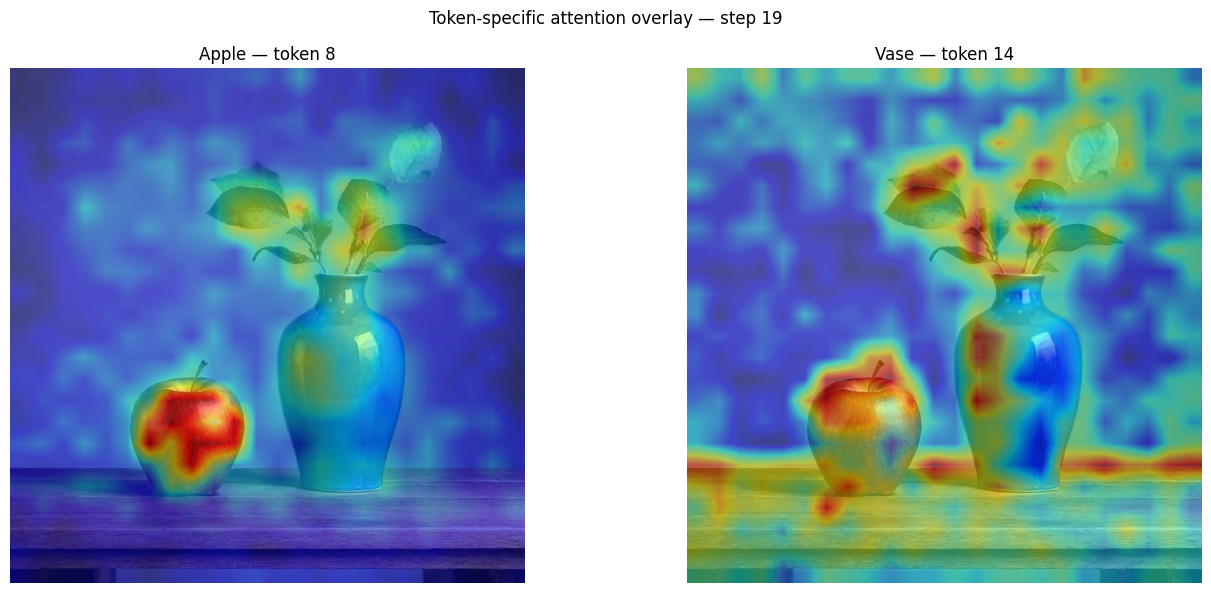

In [29]:

import numpy as np
import matplotlib.pyplot as plt

def normalize_map(attn_map):
    attn_map = np.asarray(attn_map, dtype=float)
    lo, hi = np.percentile(attn_map, [1, 99])
    return np.clip((attn_map - lo) / (hi - lo + 1e-8), 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, heat, word in [
    (axes[0], apple_map, "Apple — token 8"),
    (axes[1], vase_map, "Vase — token 14")
]:
    ax.imshow(image)
    ax.imshow(
        normalize_map(heat),
        cmap="jet",
        alpha=0.5,
        extent=(0, image.width, image.height, 0),
        interpolation="bilinear",
        vmin=0,
        vmax=1
    )
    ax.set_title(word)
    ax.axis("off")

plt.suptitle(f"Token-specific attention overlay — step {step}")
plt.tight_layout()
plt.show()
